# Revisión de resultados — BAR-ATH

Este notebook compara el scoreboard principal con las variantes de `ball_clean_ensemble`,
revisa `spellF1` por umbral de IoU, errores por posesión, transiciones y la estabilidad
del TCN entre semillas.

> El GT público se usa solo para diagnóstico. El TCN se entrenó con pseudo-etiquetas del
> `clean_ensemble`; nunca vio el GT público.


In [35]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display


def find_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "evaluation" / "possession_metrics.py").exists():
            return path
    raise RuntimeError("No encuentro la raíz del repo")


ROOT = find_root(Path.cwd())
EVAL = ROOT / "evaluation"
CLEAN = ROOT / "models" / "ball_clean_ensemble"
CLEAN_RESULTS = CLEAN / "results"
GT_PATH = EVAL / "gt" / "BAR-ATH_possession_gt_public.csv"

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(EVAL))
sys.path.insert(0, str(CLEAN))

import possession_metrics as pm
import run_tcn_variants as rv

torch.set_num_threads(1)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

print("ROOT:", ROOT)
print("GT:", GT_PATH.relative_to(ROOT))


ROOT: c:\Barcelona2026\more-than-a-hack-2027
GT: evaluation\gt\BAR-ATH_possession_gt_public.csv


## 1. Scoreboards

`evaluation/scoreboard.csv` contiene las submissions principales. El scoreboard de
`models/ball_clean_ensemble/evaluation/` contiene las variantes limpias y experimentales.


In [36]:
SCORE_COLS = [
    "rank", "submission", "spell_f1_mean", "macro_f1", "trans_f1_25",
    "poss", "dur", "fragmentation", "mean_abs_latency",
    "spell_bootstrap_low", "spell_bootstrap_high",
]


def load_board(path):
    return pd.read_csv(path).sort_values("rank").reset_index(drop=True)


main_board = load_board(EVAL / "scoreboard.csv")
clean_board = load_board(CLEAN / "evaluation" / "scoreboard.csv")

print("Scoreboard principal")
display(main_board[SCORE_COLS])

print("Variantes ball_clean_ensemble")
display(clean_board[SCORE_COLS])


Scoreboard principal


,rank,submission,spell_f1_mean,macro_f1,trans_f1_25,poss,dur,fragmentation,mean_abs_latency,spell_bootstrap_low,spell_bootstrap_high
0,1,model_tcn_clean,0.5943,0.8312,0.4186,18,13.9489,1.1429,6.8889,0.4343,0.7434
1,2,model_ensemble,0.5444,0.8148,0.3636,19,13.4442,1.1905,7.5000,0.4000,0.7000
2,3,baseline_smooth125,0.4242,0.5812,0.1667,16,18.4600,0.8095,9.0000,0.2667,0.5939
3,4,baseline_smooth50,0.3256,0.6207,0.0816,26,10.8031,1.4286,4.0000,0.2140,0.4465
4,5,baseline_smooth25,0.2868,0.6200,0.2034,36,7.5800,1.9048,9.5000,0.1962,0.3849
5,6,baseline_raw,0.0378,0.5972,0.1410,131,2.0198,6.5238,13.4545,0.0189,0.0595
6,7,my_first,0.0378,0.5972,0.1410,131,2.0198,6.5238,13.4545,0.0189,0.0595


Variantes ball_clean_ensemble


,rank,submission,spell_f1_mean,macro_f1,trans_f1_25,poss,dur,fragmentation,mean_abs_latency,spell_bootstrap_low,spell_bootstrap_high
0,1,tcn_viterbi,0.5943,0.8312,0.4186,18,13.9489,1.1429,6.8889,0.4343,0.7434
1,2,tcn_hmm_10,0.5444,0.8222,0.4091,19,13.2105,1.1905,8.2222,0.4000,0.7000
2,3,clean_ensemble,0.5444,0.8220,0.4091,19,13.2168,1.1905,8.3333,0.4000,0.7000
3,4,clean_ensemble_rawmissing,0.5444,0.8220,0.4091,19,13.2168,1.1905,8.3333,0.4000,0.7000
4,5,baseline_ensemble,0.5444,0.8148,0.3636,19,13.4442,1.1905,7.5000,0.4000,0.7000
5,6,tcn_hmm_20,0.5333,0.8223,0.4091,19,13.1432,1.1905,8.5556,0.3889,0.6778
6,7,tcn_hmm_30,0.5333,0.8219,0.4091,19,13.1389,1.1905,8.6667,0.3889,0.6778
7,8,clean_viterbi,0.5111,0.8021,0.3556,19,12.9832,1.2381,7.8750,0.3667,0.6667
8,9,clean_ensemble_centroidref,0.5081,0.8061,0.3556,20,12.5460,1.2381,8.2500,0.3676,0.6595
9,10,clean_bundesliga,0.5000,0.8033,0.3721,19,13.5200,1.1429,8.2500,0.3444,0.6444


In [37]:
def add_deltas(board, baseline="model_ensemble"):
    base = board.loc[board["submission"] == baseline]
    if base.empty:
        base = board.iloc[[0]]
    base = base.iloc[0]
    out = board.copy()
    for column in (
        "spell_f1_mean", "macro_f1", "trans_f1_25", "poss",
        "fragmentation", "mean_abs_latency",
    ):
        out["d_" + column] = out[column] - base[column]
    return out


main_delta = add_deltas(main_board)
display(main_delta[[
    "submission", "spell_f1_mean", "macro_f1",
    "d_spell_f1_mean", "d_macro_f1", "d_trans_f1_25",
    "d_poss", "d_fragmentation",
]].sort_values("d_spell_f1_mean", ascending=False))


,submission,spell_f1_mean,macro_f1,d_spell_f1_mean,d_macro_f1,d_trans_f1_25,d_poss,d_fragmentation
0,model_tcn_clean,0.5943,0.8312,0.0498,0.0165,0.0550,-1,-0.0476
1,model_ensemble,0.5444,0.8148,0.0000,0.0000,0.0000,0,0.0000
2,baseline_smooth125,0.4242,0.5812,-0.1202,-0.2336,-0.1970,-3,-0.3810
3,baseline_smooth50,0.3256,0.6207,-0.2189,-0.1941,-0.2820,7,0.2381
4,baseline_smooth25,0.2868,0.6200,-0.2577,-0.1948,-0.1602,17,0.7143
5,baseline_raw,0.0378,0.5972,-0.5066,-0.2176,-0.2226,112,5.3333
6,my_first,0.0378,0.5972,-0.5066,-0.2176,-0.2226,112,5.3333


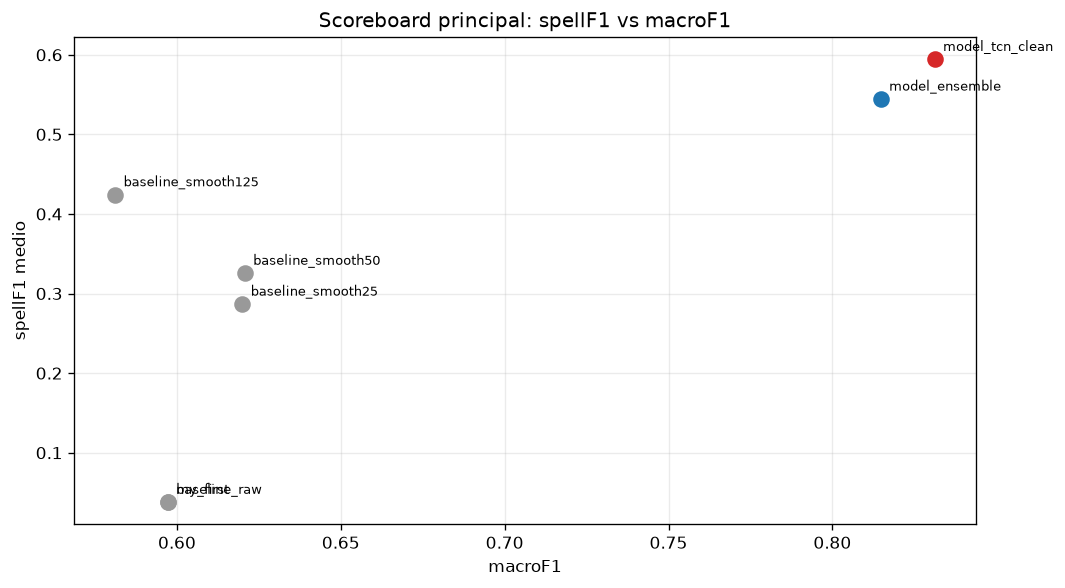

In [38]:
fig, ax = plt.subplots(figsize=(9, 5))
for _, row in main_board.iterrows():
    name = row["submission"]
    color = "#d62728" if name == "model_tcn_clean" else (
        "#1f77b4" if name == "model_ensemble" else "#999999")
    ax.scatter(row["macro_f1"], row["spell_f1_mean"], s=80, color=color, zorder=3)
    ax.annotate(name, (row["macro_f1"], row["spell_f1_mean"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)

ax.set_xlabel("macroF1")
ax.set_ylabel("spellF1 medio")
ax.set_title("Scoreboard principal: spellF1 vs macroF1")
plt.tight_layout()
plt.show()


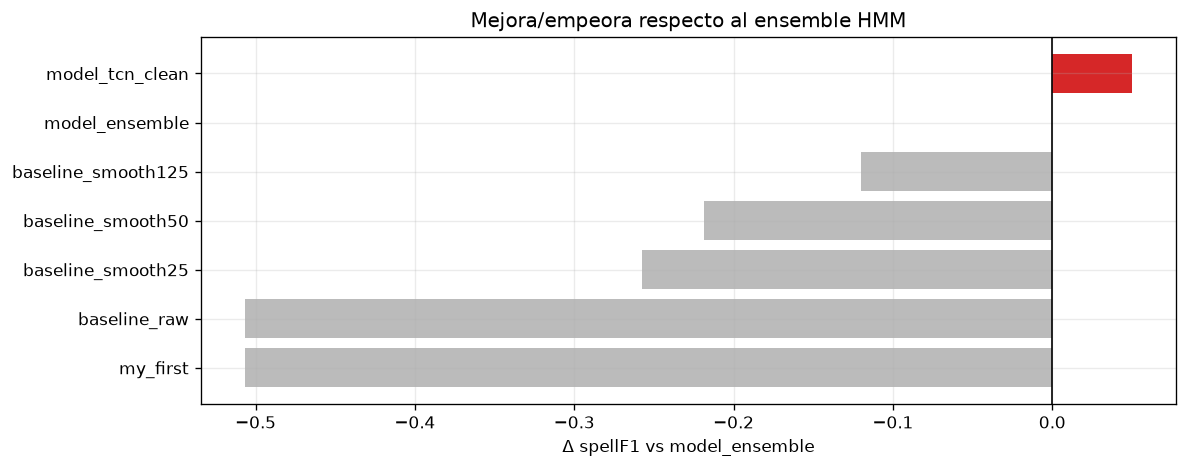

In [39]:
plot = main_delta.sort_values("d_spell_f1_mean")
colors = [
    "#d62728" if name == "model_tcn_clean" else
    "#1f77b4" if name == "model_ensemble" else "#bbbbbb"
    for name in plot["submission"]
]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(plot["submission"], plot["d_spell_f1_mean"], color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Δ spellF1 vs model_ensemble")
ax.set_title("Mejora/empeora respecto al ensemble HMM")
plt.tight_layout()
plt.show()


## 2. `spellF1` por umbral de IoU

El scoreboard usa la media de IoU `0.3, 0.4, 0.5, 0.6, 0.7`. Mirar el perfil completo
distingue un modelo que acierta posesiones largas de uno que solo acierta los bordes.


In [40]:
CANDIDATES = {
    "model_tcn_clean": EVAL / "results" / "model_tcn_clean.csv",
    "model_ensemble": EVAL / "results" / "model_ensemble.csv",
    "clean_ensemble": CLEAN_RESULTS / "clean_ensemble.csv",
    "tcn_clean_debounce25": CLEAN_RESULTS / "tcn_clean_debounce25.csv",
    "tcn_clean_raw": CLEAN_RESULTS / "tcn_clean_raw.csv",
}


def read_codes(path):
    return pm.label_codes(pm.read_label_csv(path))


gt = pm.label_codes(pm.read_label_csv(GT_PATH))
runs = pm.valid_runs(gt)

iou_rows = []
for name, path in CANDIDATES.items():
    pred = read_codes(path)
    scores = pm.spell_scores(gt, pred, runs)
    row = {
        "submission": name,
        "mean": scores["mean_f1"],
        "n_gt": scores["n_gt"],
        "n_pred": scores["n_pred"],
    }
    for iou, metrics in scores["per_iou"].items():
        row[f"IoU {iou:.1f}"] = metrics["f1"]
    iou_rows.append(row)

iou_table = pd.DataFrame(iou_rows).sort_values("mean", ascending=False)
display(iou_table)


,submission,mean,n_gt,n_pred,IoU 0.3,IoU 0.4,IoU 0.5,IoU 0.6,IoU 0.7
0,model_tcn_clean,0.5943,17,18,0.6857,0.6857,0.6857,0.5143,0.4000
1,model_ensemble,0.5444,17,19,0.6667,0.6667,0.6111,0.4444,0.3333
2,clean_ensemble,0.5444,17,19,0.6667,0.6667,0.6111,0.4444,0.3333
3,tcn_clean_debounce25,0.4878,17,24,0.6341,0.5854,0.5366,0.3902,0.2927
4,tcn_clean_raw,0.2892,17,48,0.4000,0.4000,0.3077,0.2154,0.1231


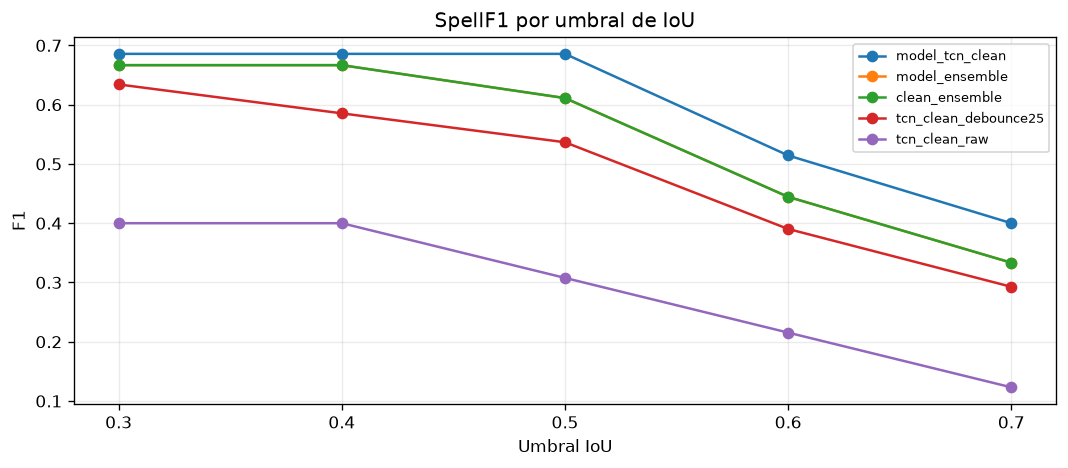

In [41]:
iou_cols = [column for column in iou_table.columns if column.startswith("IoU ")]
thresholds = [float(column.split()[1]) for column in iou_cols]

fig, ax = plt.subplots(figsize=(9, 4))
for _, row in iou_table.iterrows():
    ax.plot(thresholds, row[iou_cols].values, marker="o", label=row["submission"])
ax.set_xlabel("Umbral IoU")
ax.set_ylabel("F1")
ax.set_title("SpellF1 por umbral de IoU")
ax.set_xticks(thresholds)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 3. Transiciones y estructura de posesiones

`transF1` cuenta cambios de posesión con tolerancia. También revisamos el número de
posesiones, duración media, fragmentación y latencia.


In [42]:
def transition_rows(path):
    pred = read_codes(path)
    filled = pm.fill_abstentions(pred, runs)
    gt_trans = pm.transitions(gt, runs)
    pred_trans = pm.transitions(filled, runs)
    rows = []
    for tau in (12, 25, 50):
        scores = pm.transition_scores(gt_trans, pred_trans, tau)
        rows.append({
            "submission": path.stem,
            "tau": tau,
            "precision": scores["precision"],
            "recall": scores["recall"],
            "f1": scores["f1"],
            "matched": scores["n_matched"],
            "missed": scores["n_missed"],
            "spurious": scores["n_spurious"],
            "mean_latency": scores["mean_latency"],
        })
    return rows


trans_rows = []
for path in CANDIDATES.values():
    trans_rows.extend(transition_rows(path))
trans_table = pd.DataFrame(trans_rows)

display(trans_table.pivot(index="submission", columns="tau", values="f1")
        .rename(columns=lambda tau: f"transF1 @{tau}"))
display(trans_table[trans_table["tau"] == 25]
        .sort_values("f1", ascending=False)
        .reset_index(drop=True))


tau,transF1 @12,transF1 @25,transF1 @50
submission,,,
clean_ensemble,0.2727,0.4091,0.4091
model_ensemble,0.2727,0.3636,0.3636
model_tcn_clean,0.3721,0.4186,0.4186
tcn_clean_debounce25,0.3200,0.4400,0.4400
tcn_clean_raw,0.2078,0.3377,0.3377


,submission,tau,precision,recall,f1,matched,missed,spurious,mean_latency
0,tcn_clean_debounce25,25,0.3667,0.5500,0.4400,11,9,19,-2.0909
1,model_tcn_clean,25,0.3913,0.4500,0.4186,9,11,14,-1.1111
2,clean_ensemble,25,0.3750,0.4500,0.4091,9,11,15,-1.8889
3,model_ensemble,25,0.3333,0.4000,0.3636,8,12,16,-0.2500
4,tcn_clean_raw,25,0.2281,0.6500,0.3377,13,7,44,0.9231


,submission,spell_f1_mean,poss,dur,fragmentation,mean_abs_latency,share_err
0,model_tcn_clean,0.5943,18,13.9489,1.1429,6.8889,0.0073
1,model_ensemble,0.5444,19,13.4442,1.1905,7.5000,0.0054
2,baseline_smooth125,0.4242,16,18.4600,0.8095,9.0000,0.0520
3,baseline_smooth50,0.3256,26,10.8031,1.4286,4.0000,0.0485
4,baseline_smooth25,0.2868,36,7.5800,1.9048,9.5000,0.0556
5,baseline_raw,0.0378,131,2.0198,6.5238,13.4545,0.0457
6,my_first,0.0378,131,2.0198,6.5238,13.4545,0.0457


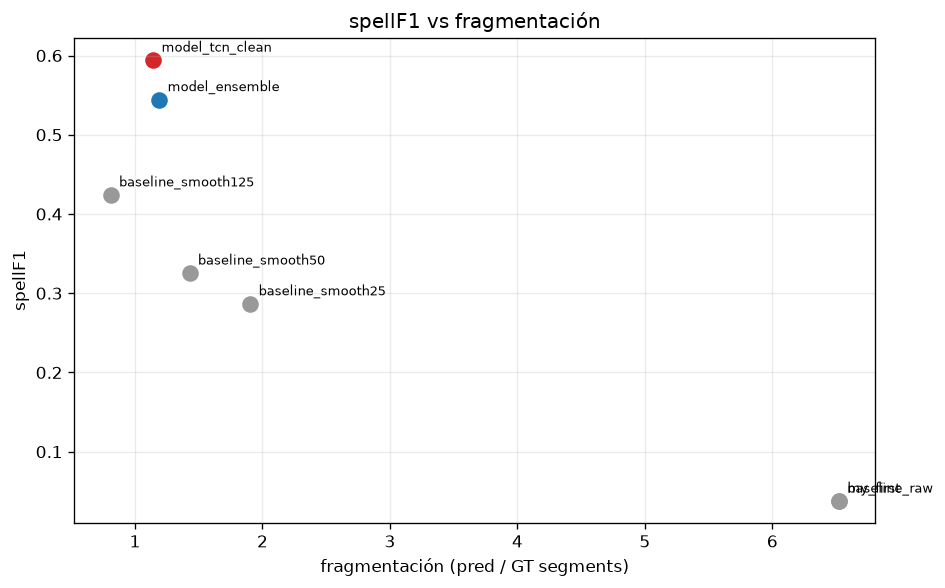

In [43]:
diag_cols = [
    "submission", "spell_f1_mean", "poss", "dur",
    "fragmentation", "mean_abs_latency", "share_err",
]
display(main_board[diag_cols])

fig, ax = plt.subplots(figsize=(8, 5))
for _, row in main_board.iterrows():
    name = row["submission"]
    color = "#d62728" if name == "model_tcn_clean" else (
        "#1f77b4" if name == "model_ensemble" else "#999999")
    ax.scatter(row["fragmentation"], row["spell_f1_mean"], s=80, color=color)
    ax.annotate(name, (row["fragmentation"], row["spell_f1_mean"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xlabel("fragmentación (pred / GT segments)")
ax.set_ylabel("spellF1")
ax.set_title("spellF1 vs fragmentación")
plt.tight_layout()
plt.show()


## 4. Errores por posesión

Cambia `TARGET` para inspeccionar otra submission. `MATCH` usa IoU >= 0.5.


In [44]:
TARGET = "model_tcn_clean"
target = read_codes(CANDIDATES[TARGET])
gt_spells = pm.possession_spells(gt, runs)
pred_spells = pm.possession_spells(target, runs)
overlaps = pm.spell_overlaps(gt_spells, pred_spells)

gt_best = {}
pred_best = {}
for iou, gt_index, pred_index in overlaps:
    gt_best.setdefault(gt_index, (iou, pred_index))
    pred_best.setdefault(pred_index, (iou, gt_index))

gt_rows = []
for index, (start, stop, code) in enumerate(gt_spells):
    best = gt_best.get(index)
    gt_rows.append({
        "gt": index,
        "team": pm.LABELS[code],
        "start": start,
        "stop": stop,
        "dur_s": (stop - start) / pm.FPS,
        "best_iou": best[0] if best else 0.0,
        "pred": best[1] if best else None,
        "status": "MATCH" if best and best[0] >= 0.5 else (
            "MISS" if best else "NO OVERLAP"),
    })

pred_rows = []
for index, (start, stop, code) in enumerate(pred_spells):
    best = pred_best.get(index)
    pred_rows.append({
        "pred": index,
        "team": pm.LABELS[code],
        "start": start,
        "stop": stop,
        "dur_s": (stop - start) / pm.FPS,
        "best_iou": best[0] if best else 0.0,
        "gt": best[1] if best else None,
        "status": "MATCH" if best and best[0] >= 0.5 else (
            "SPURIOUS" if best else "NO OVERLAP"),
    })

gt_table = pd.DataFrame(gt_rows)
pred_table = pd.DataFrame(pred_rows)

print(f"{TARGET}: GT={len(gt_spells)} posesiones, pred={len(pred_spells)}")
print("GT no matcheadas")
display(gt_table[gt_table["status"] != "MATCH"])
print("Predicciones no matcheadas")
display(pred_table[pred_table["status"] != "MATCH"])


model_tcn_clean: GT=17 posesiones, pred=18
GT no matcheadas


,gt,team,start,stop,dur_s,best_iou,pred,status
1,1,H,11351,11553,8.0800,0.2266,1.0000,MISS
2,2,A,11553,11624,2.8400,0.0000,NaN,NO OVERLAP
9,9,H,15346,15365,0.7600,0.0000,NaN,NO OVERLAP
10,10,A,15365,15766,16.0400,0.3080,8.0000,MISS
11,11,H,15766,15799,1.3200,0.0000,NaN,NO OVERLAP


Predicciones no matcheadas


,pred,team,start,stop,dur_s,best_iou,gt,status
1,1,H,11473,11704,9.2400,0.2266,1.0000,SPURIOUS
2,2,A,11704,11796,3.6800,0.0000,NaN,NO OVERLAP
9,9,H,15649,15744,3.8000,0.0000,NaN,NO OVERLAP
11,11,H,16010,16090,3.2000,0.0000,NaN,NO OVERLAP
12,12,H,16152,16278,5.0400,0.0000,NaN,NO OVERLAP
13,13,A,16278,16625,13.8800,0.2217,13.0000,SPURIOUS


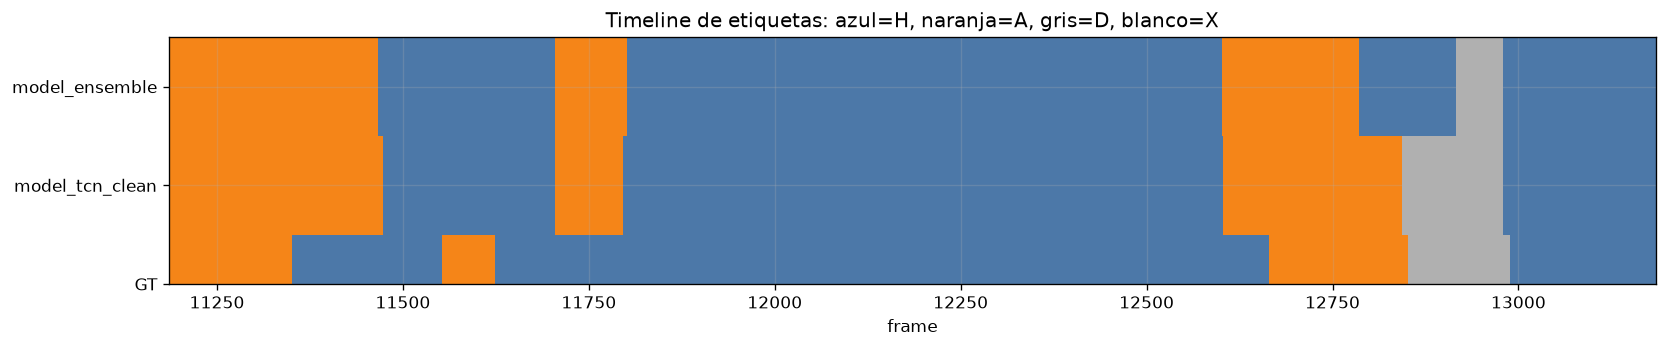

In [45]:
WINDOW_START = 11185
WINDOW_STOP = 13185
row_names = ["GT", TARGET, "model_ensemble"]

from matplotlib.colors import ListedColormap

label_cmap = ListedColormap(["#4c78a8", "#f58518", "#b0b0b0", "#ffffff"])

fig, ax = plt.subplots(figsize=(14, 3))
for row_index, name in enumerate(row_names):
    labels = gt if name == "GT" else read_codes(CANDIDATES[name])
    ax.imshow(
        labels[None, WINDOW_START:WINDOW_STOP],
        aspect="auto",
        interpolation="nearest",
        origin="lower",
        extent=[WINDOW_START, WINDOW_STOP, row_index, row_index + 1],
        cmap=label_cmap,
        vmin=-0.5,
        vmax=3.5,
    )

ax.set_yticks([0.5, 1.5, 2.5])
ax.set_yticklabels(row_names)
ax.set_xlabel("frame")
ax.set_title("Timeline de etiquetas: azul=H, naranja=A, gris=D, blanco=X")
plt.tight_layout()
plt.show()


## 5. Estabilidad del TCN entre semillas

Entrenamos varias semillas con la misma configuración. Un solo seed puede parecer mejor
por azar; el ensemble promedia probabilidades y suele ser más estable.


In [46]:
SEED_PATHS = {
    "seed7": CLEAN / "tcn_clean_logits.npz",
    "seed1": CLEAN / "tcn_clean_logits_seed1.npz",
    "seed2": CLEAN / "tcn_clean_logits_seed2.npz",
    "seed11": CLEAN / "tcn_clean_logits_seed11.npz",
    "seed23": CLEAN / "tcn_clean_logits_seed23.npz",
    "seed42": CLEAN / "tcn_clean_logits_seed42.npz",
    "ensemble": CLEAN / "tcn_clean_logits_ensemble.npz",
}

_, _, arrays = rv._load(str(CLEAN / "tcn_clean_logits_ensemble.npz"))


def decode_tcn_logits(path, min_spell=62, scale=0.8):
    with np.load(path) as bundle:
        logits = bundle["logits"].astype(np.float64)
    log_probs = torch.log_softmax(torch.from_numpy(logits), dim=1).numpy()
    return rv._decode(log_probs * scale, arrays, min_spell, refine=False)


seed_rows = []
for name, path in SEED_PATHS.items():
    labels = decode_tcn_logits(path)
    result = pm.evaluate(gt, labels)
    seed_rows.append({
        "model": name,
        "spellF1": result["spell_f1_mean"],
        "macroF1": result["macro_f1"],
        "transF1@25": result["transitions"][25]["f1"],
        "poss": result["n_pred_spells"],
    })

seed_table = pd.DataFrame(seed_rows).sort_values("spellF1", ascending=False)
display(seed_table)


Computing hierarchical emission distributions...
Computing emissions using Bundesliga-trained weights...


,model,spellF1,macroF1,transF1@25,poss
5,seed42,0.6118,0.8161,0.4390,17
4,seed23,0.6057,0.8313,0.4186,18
1,seed1,0.5943,0.8300,0.4186,18
6,ensemble,0.5943,0.8312,0.4186,18
3,seed11,0.5829,0.8329,0.4186,18
0,seed7,0.5789,0.8222,0.4783,21
2,seed2,0.5600,0.8276,0.4651,18


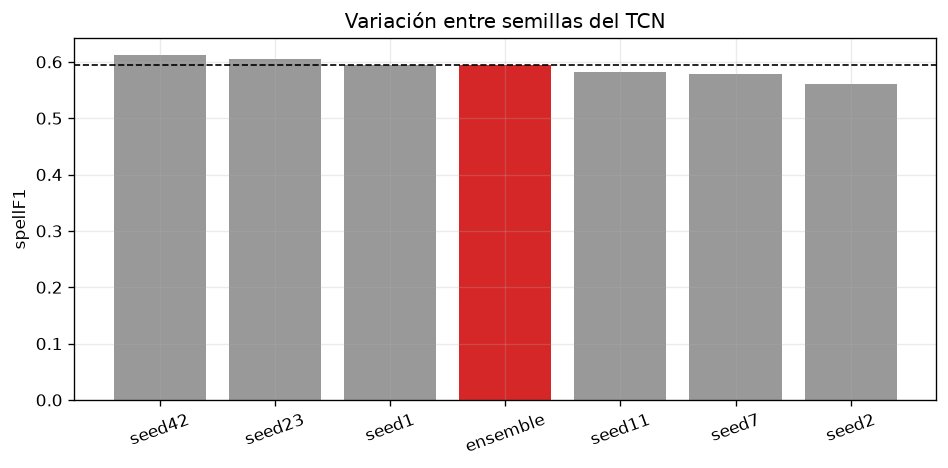

In [47]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#d62728" if name == "ensemble" else "#999999"
          for name in seed_table["model"]]
ax.bar(seed_table["model"], seed_table["spellF1"], color=colors)
ax.axhline(
    seed_table.loc[seed_table["model"] == "ensemble", "spellF1"].iloc[0],
    color="black", linestyle="--", linewidth=1,
)
ax.set_ylabel("spellF1")
ax.set_title("Variación entre semillas del TCN")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


In [48]:
boot_rows = []
for name in ["model_tcn_clean", "model_ensemble", "clean_ensemble"]:
    pred = read_codes(CANDIDATES[name])
    mean = pm.spell_scores(gt, pred, runs)["mean_f1"]
    low, high = pm.bootstrap_spell_f1(gt, pred, runs, n_draws=1000)
    boot_rows.append({
        "submission": name,
        "spellF1": mean,
        "bootstrap_low": low,
        "bootstrap_high": high,
    })

display(pd.DataFrame(boot_rows))


,submission,spellF1,bootstrap_low,bootstrap_high
0,model_tcn_clean,0.5943,0.4343,0.7434
1,model_ensemble,0.5444,0.4000,0.7000
2,clean_ensemble,0.5444,0.4000,0.7000


## Lectura rapida

- `model_tcn_clean` es el ensemble de 6 TCN. Gana en `spellF1`, `macroF1`, transiciones,
  fragmentaci?n y duraci?n media.
- `model_tcn_clean.csv` y `tcn_viterbi.csv` son el mismo resultado.
- La diferencia contra `model_ensemble` sigue dentro del ruido bootstrap: el GT p?blico
  solo tiene 17 posesiones.
- El mayor error restante son posesiones cortas y transiciones alrededor de bal?n muerto.
  Un decoder con modelo de duraci?n (HSMM) es la siguiente v?a razonable.
- El TCN solo con `debounce` no basta; la mejora aparece al usar sus logits como emisiones
  dentro de Viterbi con `min_spell=62`.

### Regenerar el candidato

```powershell
python models/ball_clean_ensemble/train_tcn_clean.py --seed 7 --skip-variants
python models/ball_clean_ensemble/train_tcn_clean.py --seed 1  --tag seed1  --skip-variants
python models/ball_clean_ensemble/train_tcn_clean.py --seed 2  --tag seed2  --skip-variants
python models/ball_clean_ensemble/train_tcn_clean.py --seed 11 --tag seed11 --skip-variants
python models/ball_clean_ensemble/train_tcn_clean.py --seed 23 --tag seed23 --skip-variants
python models/ball_clean_ensemble/train_tcn_clean.py --seed 42 --tag seed42 --skip-variants

python models/ball_clean_ensemble/ensemble_tcn_logits.py `
  --inputs `
    models/ball_clean_ensemble/tcn_clean_logits.npz `
    models/ball_clean_ensemble/tcn_clean_logits_seed1.npz `
    models/ball_clean_ensemble/tcn_clean_logits_seed2.npz `
    models/ball_clean_ensemble/tcn_clean_logits_seed11.npz `
    models/ball_clean_ensemble/tcn_clean_logits_seed23.npz `
    models/ball_clean_ensemble/tcn_clean_logits_seed42.npz `
  --out models/ball_clean_ensemble/tcn_clean_logits_ensemble.npz

python models/ball_clean_ensemble/run_tcn_variants.py
python evaluation/run_evaluation.py --gt public --bootstrap 1000
```

La guia completa esta en `models/ball_clean_ensemble/README.md`.
